In [42]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score 
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from model import normalize_record

In [43]:
url = 'https://raw.githubusercontent.com/zm412/machine-learning-zoomcamp/refs/heads/main/midterm/automated_recruitment_analytics.csv'

In [44]:
df = pd.read_csv(url)

In [45]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [46]:
df['outcome'] = (df['outcome'] == 'Hired').astype(int)

In [47]:
df.columns

Index(['candidate_id', 'resume_text', 'skills', 'education',
       'experience_years', 'job_id', 'job_title', 'required_skills',
       'job_fit_score', 'outcome'],
      dtype='str')

In [48]:
df.head()

,candidate_id,resume_text,skills,education,experience_years,job_id,job_title,required_skills,job_fit_score,outcome
0,CAND00001,Candidate profile: MBA; professional experienc...,"Performance Tuning, Statistics",MBA,1,JOB0103,Web Developer,"Git, JavaScript, CSS, HTML",0.1093,0
1,CAND00002,Aditya is a B.Tech graduate with 10 years of e...,"Kubernetes, Machine Learning, MLOps, Excel, SQ...",B.Tech,10,JOB0088,Machine Learning Engineer,"Machine Learning, MLOps, Python, Deep Learning",1.0000,1
2,CAND00003,Rahul completed B.Sc and has worked for 9 year...,SIEM,B.Sc,9,JOB0158,Cloud Engineer,"Networking, Docker, Linux, Python, AWS",0.3707,0
3,CAND00004,Aditya completed B.E. and has worked for 2 yea...,"PyTorch, Python, Backup and Recovery",B.E.,2,JOB0059,Database Administrator,"PostgreSQL, Linux, Database Design, Performanc...",0.2259,0
4,CAND00005,Manoj has 4 years of professional experience a...,SQL,M.Sc,4,JOB0064,HR Analyst,"HR Analytics, SQL, Power BI, Excel, Communication",0.2679,0


In [49]:
df.isnull().sum()

candidate_id        0
resume_text         0
skills              0
education           0
experience_years    0
job_id              0
job_title           0
required_skills     0
job_fit_score       0
outcome             0
dtype: int64

In [50]:
df.dtypes

candidate_id            str
resume_text             str
skills                  str
education               str
experience_years      int64
job_id                  str
job_title               str
required_skills         str
job_fit_score       float64
outcome               int64
dtype: object

In [51]:
del df['candidate_id']
del df['resume_text']
del df['job_fit_score']
del df['job_id']

In [52]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['outcome'].values
y_val = df_val['outcome'].values
y_test = df_test['outcome'].values

In [53]:
del df_train['outcome']
del df_val['outcome']
del df_test['outcome']

In [54]:
train_dicts = normalize_record(df_train.to_dict(orient="records"))
val_dicts = normalize_record(df_val.to_dict(orient='records'))

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [59]:
def check_best_logistic_auc():
    scores = []

    for c_val in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]:
        lr_model = LogisticRegression(
            C=c_val,
            max_iter=1000,
            class_weight='balanced',
            random_state=42,
        )
        lr_model.fit(X_train, y_train)

        y_pred = lr_model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((c_val, auc, y_pred))

    columns = ['C', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [60]:
def check_best_decision_tree_auc():
    scores = []

    for depth in [4, 5, 6]:
        for s in [1, 5, 10, 15, 20, 500, 100, 200]:
            dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
            dt.fit(X_train, y_train)

            y_pred = dt.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            
            scores.append((depth, s, auc, y_pred))
    columns = ['max_depth', 'min_samples_leaf', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [61]:
def check_best_forest_auc():
    scores = []

    for n in [10, 50, 100, 200]:
        for max_depth in range(10, 201, 10):
            rf = RandomForestClassifier(
              n_estimators=n,
              max_depth=max_depth,
              random_state=42,
              class_weight='balanced',
              n_jobs=-1,
            )
            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)

            scores.append((n, max_depth, auc, y_pred))

    columns = ['n_estimators', 'max_depth', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [62]:
def check_best_xgb_auc():
    scores = []

    for eta in [0.05, 0.1, 0.3]:
        for max_depth in [3, 5, 10]:
            for n_estimators in [50, 100, 200]:
                xgb_model = xgb.XGBClassifier(
                    learning_rate=eta,
                    max_depth=max_depth,
                    n_estimators=n_estimators,
                    random_state=42,
                    n_jobs=-1,
                )
                xgb_model.fit(X_train, y_train)

                y_pred = xgb_model.predict_proba(X_val)[:, 1]
                auc = roc_auc_score(y_val, y_pred)

                scores.append((eta, max_depth, n_estimators, auc, y_pred))

    columns = ['learning_rate', 'max_depth', 'n_estimators', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [110]:
def get_comparison_result(best_threshold):
    lr = check_best_logistic_auc()
    dt = check_best_decision_tree_auc()
    rf = check_best_forest_auc()
    xgb = check_best_xgb_auc()

    comparison_df = pd.DataFrame({
        'act': y_val,
        'lr': (lr.y_pred >= best_threshold).astype(int),
        'dt': (dt.y_pred >= best_threshold).astype(int),
        'rf': (rf.y_pred >= best_threshold).astype(int),
        'xgb': (xgb.y_pred >= best_threshold).astype(int),
    })

    return comparison_df

In [111]:
def get_comparison_auc_result():
  lr = check_best_logistic_auc()
  dt = check_best_decision_tree_auc()
  rf = check_best_forest_auc()
  xgb = check_best_xgb_auc()

  comparison_dict = {
      'lr': [lr.auc],
      'dt': [dt.auc],
      'rf': [rf.auc],
      'xgb': [xgb.auc],
  }

  return pd.DataFrame(comparison_dict)

In [112]:
print(get_comparison_auc_result())


        lr        dt       rf      xgb
0  0.92463  0.824807  0.90991  0.91735


In [119]:
check_best_logistic_auc()

C                                                       1.0
auc                                                 0.92463
y_pred    [0.043088632387497904, 0.34950986517613314, 0....
Name: 3, dtype: object

In [120]:
model = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

In [121]:
def research_best_model(y_pred):
    thresholds = np.linspace(0, 1, 101)
    f1_scores = []
    precisions = []
    recalls = []

    for t in thresholds:
        y_pred_bin = (y_pred >= t).astype(int)

        precisions.append(precision_score(y_val, y_pred_bin, zero_division=0))
        recalls.append(recall_score(y_val, y_pred_bin, zero_division=0))

        score = f1_score(y_val, y_pred_bin, zero_division=0)
        f1_scores.append(score)

    best_t_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_t_idx]
    best_f1 = f1_scores[best_t_idx]

    print(
        f'Optimal Threshold by F1-Score: {best_threshold:.2f} with F1:'
        f' {best_f1:.4f}'
    )

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, precisions, label='Precision', color='blue', linestyle='--')
    plt.plot(thresholds, recalls, label='Recall', color='green', linestyle='--')
    plt.plot(thresholds, f1_scores, label='F1-Score', color='red', linewidth=2)

    plt.axvline(x=best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})',)
    plt.title('Precision, Recall, F1-Score')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

Optimal Threshold by F1-Score: 0.59 with F1: 0.6441


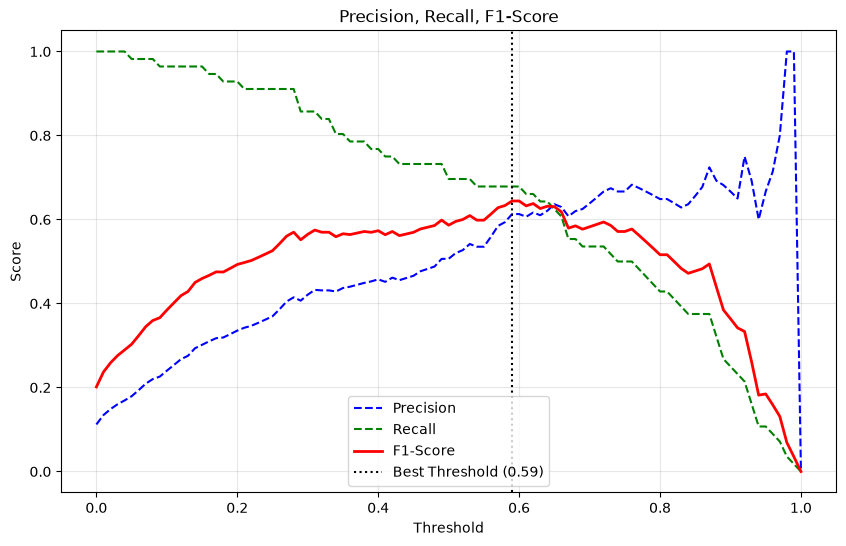

In [123]:
research_best_model(y_pred)

In [118]:
heavy_comparison = 

     act  lr  dt  rf  xgb
0      0   0   0   0    0
1      0   0   0   0    0
2      0   0   0   0    0
3      1   1   0   0    0
4      0   0   0   0    0
..   ...  ..  ..  ..  ...
495    0   0   0   0    0
496    0   0   0   0    0
497    0   0   0   0    0
498    0   0   0   0    0
499    0   0   0   0    0

[500 rows x 5 columns]
